# Document Chunking Utility Demo

This notebook shows the workflow of the Document Chunking Utility. The utility is a Python command-line tool that splits `.txt` and `.md` documents into smaller and cleaner chunks. It also adds useful metadata to each chunk.

The utility supports three chunking methods:

1. **Paragraph-based chunking** — splits documents at blank lines to keep the natural paragraph structure. For Markdown files, short headings that appear by themselves are attached to the content that follows them.
2. **Bounded paragraph chunking** — keeps normal paragraphs together when possible and attaches short Markdown headings to the following content. If a paragraph is too large, it is split into smaller chunks so that each chunk stays within the token limit. This method also keeps the exact text from the source document. The original document can be rebuilt by joining the bounded chunks in the correct order.
3. **Fixed-size word chunking** — splits documents into chunks with a set number of words. It can also include optional overlap between chunks.

Each chunk contains useful metadata. This includes the source filename, source path, configuration-based chunk ID, chunk index, character offsets, word count, and character count. The chunk ID is created using the source identity, chunking method, related chunking settings, and chunk index. Bounded paragraph chunks also include the token count, maximum token limit, and tokenizer information.

The results can be saved as CSV or JSONL files. These files can then be used for NLP tasks such as retrieval, summarization, classification, and preparing text data for further processing.

This demo also checks for traceability and chunk identity. It verifies that the saved character offsets can be used to get the exact chunk text from the original source file. It also checks that the same source document receives different chunk IDs when different chunking settings are used. For bounded paragraph chunking, the demo checks that the chunks are continuous and that joining their `chunk_text` values in order recreates the full original document exactly.

## Notebook setup note

This demo assumes the notebook is being run from the project repository. Create a virtual environment, install the project, and then start Jupyter.

### Windows (Command Prompt)

```bat
python -m venv .venv
```

```bat
.venv\Scripts\activate.bat
```

```bat
python -m pip install --upgrade pip
```

```bat
python -m pip install -e ".[demo]"
```

```bat
python -m jupyter notebook
```

### macOS / Linux

```bash
python3 -m venv .venv
```

```bash
source .venv/bin/activate
```

```bash
python -m pip install --upgrade pip
```

```bash
python -m pip install -e ".[demo]"
```

```bash
python -m jupyter notebook
```

After Jupyter opens, go to the `notebooks/` folder and open this notebook.

The examples below use the sample documents in:

```text
examples/sample_docs/
```

Generated demo outputs are written into a temporary directory at:

```text
tmp/notebook_demo/
```


In [1]:
import json
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from document_chunking_utility.io import read_text_file

PROJ_ROOT = Path.cwd()

if not (PROJ_ROOT / "pyproject.toml").exists():
    PROJ_ROOT = PROJ_ROOT.parent

if not (PROJ_ROOT / "pyproject.toml").exists():
    raise FileNotFoundError("Run this notebook from the project root or notebooks folder.")

smpl_DOCS = PROJ_ROOT / "examples" / "sample_docs"
OUTPUT_DIR = PROJ_ROOT / "tmp" / "notebook_demo"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root: .")
print(f"Sample documents: {smpl_DOCS.relative_to(PROJ_ROOT)}")
print(f"Demo output directory: {OUTPUT_DIR.relative_to(PROJ_ROOT)}")

Project root: .
Sample documents: examples/sample_docs
Demo output directory: tmp/notebook_demo


In [2]:
# List the sample input documents that will be chunked.

smpl_files = sorted(
    [
        file
        for file in smpl_DOCS.rglob("*")
        if file.is_file() and file.suffix.lower() in {".txt", ".md"}
    ]
)

print(f"Found {len(smpl_files)} supported sample document(s):")
print()

for file in smpl_files:
    print(file.relative_to(PROJ_ROOT))

Found 2 supported sample document(s):

examples/sample_docs/campus_garden_notes.txt
examples/sample_docs/project_meeting_notes.md


In [3]:
# Preview the first sample document.

if not smpl_files:
    raise FileNotFoundError(f"No supported .txt or .md files found in {smpl_DOCS}")

prev_file = smpl_files[0]
prev_text = read_text_file(prev_file)

print(f"Preview file: {prev_file.relative_to(PROJ_ROOT)}")
print("-" * 80)
print(prev_text[:1000])

if len(prev_text) > 1000:
    print("\n... preview truncated ...")

Preview file: examples/sample_docs/campus_garden_notes.txt
--------------------------------------------------------------------------------
Campus Garden Notes

The campus garden looks different in the morning because the east side gets sunlight first. Most of the tomatoes are still green, but the basil plants are growing quickly near the wooden fence.

The student volunteers watered the raised beds after lunch. One group also pulled weeds around the peppers because the smaller plants were starting to get covered.

Next week, the club should bring extra gloves and mark which beds have already been watered. The handwritten labels are starting to fade, especially near the herb section.


In [4]:
# Run paragraph-based chunking using the CLI interface.

paragraph_out = OUTPUT_DIR / "demo_paragraph_chunks.csv"

paragraph_cmd = [
    sys.executable,
    "-m",
    "document_chunking_utility",
    "chunk",
    str(smpl_DOCS.relative_to(PROJ_ROOT)),
    "--method",
    "paragraph",
    "--out",
    str(paragraph_out.relative_to(PROJ_ROOT)),
]

result = subprocess.run(
    paragraph_cmd,
    capture_output=True,
    text=True,
    cwd=PROJ_ROOT,
    check=False,
)

disp_cmd = paragraph_cmd.copy()
disp_cmd[0] = "python"

print("Command:")
print(" ".join(disp_cmd))
print()
print("CLI output:")
print(result.stdout)

if result.stderr:
    print("CLI errors or warnings:")
    print(result.stderr)

if result.returncode != 0:
    raise RuntimeError("Paragraph chunking command failed.")

print(f"Paragraph chunk output created at: {paragraph_out.relative_to(PROJ_ROOT)}")


Command:
python -m document_chunking_utility chunk examples/sample_docs --method paragraph --out tmp/notebook_demo/demo_paragraph_chunks.csv

CLI output:
Input directory: examples/sample_docs
Method: paragraph

Processed files: 2
Unsupported files skipped: 0
Empty files skipped: 0
Total chunks: 7
Average words per chunk: 25.6
Shortest chunk: 3 words
Longest chunk: 37 words
Output file: tmp/notebook_demo/demo_paragraph_chunks.csv

Paragraph chunk output created at: tmp/notebook_demo/demo_paragraph_chunks.csv


In [5]:
# Load and inspect the paragraph chunking output.

paragraph_df = pd.read_csv(paragraph_out)

print(f"Paragraph chunks generated: {len(paragraph_df)}")
print(f"Columns: {list(paragraph_df.columns)}")

paragraph_df.head()

Paragraph chunks generated: 7
Columns: ['chunk_id', 'source_file', 'source_path', 'method', 'chunk_size', 'overlap', 'token_count', 'max_tokens', 'tokenizer', 'chunk_index', 'chunk_text', 'start_char', 'end_char', 'char_count', 'word_count']


,chunk_id,source_file,source_path,method,chunk_size,overlap,token_count,max_tokens,tokenizer,chunk_index,chunk_text,start_char,end_char,char_count,word_count
0,campus_garden_notes_txt_fe25b38b_paragraph_000,campus_garden_notes.txt,campus_garden_notes.txt,paragraph,NaN,NaN,NaN,NaN,NaN,0,Campus Garden Notes,0,19,19,3
1,campus_garden_notes_txt_fe25b38b_paragraph_001,campus_garden_notes.txt,campus_garden_notes.txt,paragraph,NaN,NaN,NaN,NaN,NaN,1,The campus garden looks different in the morni...,23,216,193,33
2,campus_garden_notes_txt_fe25b38b_paragraph_002,campus_garden_notes.txt,campus_garden_notes.txt,paragraph,NaN,NaN,NaN,NaN,NaN,2,The student volunteers watered the raised beds...,220,383,163,26
3,campus_garden_notes_txt_fe25b38b_paragraph_003,campus_garden_notes.txt,campus_garden_notes.txt,paragraph,NaN,NaN,NaN,NaN,NaN,3,"Next week, the club should bring extra gloves ...",387,558,171,28
4,project_meeting_notes_md_4ddcb141_paragraph_000,project_meeting_notes.md,project_meeting_notes.md,paragraph,NaN,NaN,NaN,NaN,NaN,0,# Project Meeting Notes\r\n\r\n## Attendance\r...,0,152,152,24


In [6]:
# Display selected metadata fields for paragraph chunks.

paragraph_prev_col = [
    "chunk_id",
    "source_file",
    "method",
    "chunk_index",
    "word_count",
    "char_count",
    "start_char",
    "end_char",
    "chunk_text",
]

paragraph_df[paragraph_prev_col].head()


,chunk_id,source_file,method,chunk_index,word_count,char_count,start_char,end_char,chunk_text
0,campus_garden_notes_txt_fe25b38b_paragraph_000,campus_garden_notes.txt,paragraph,0,3,19,0,19,Campus Garden Notes
1,campus_garden_notes_txt_fe25b38b_paragraph_001,campus_garden_notes.txt,paragraph,1,33,193,23,216,The campus garden looks different in the morni...
2,campus_garden_notes_txt_fe25b38b_paragraph_002,campus_garden_notes.txt,paragraph,2,26,163,220,383,The student volunteers watered the raised beds...
3,campus_garden_notes_txt_fe25b38b_paragraph_003,campus_garden_notes.txt,paragraph,3,28,171,387,558,"Next week, the club should bring extra gloves ..."
4,project_meeting_notes_md_4ddcb141_paragraph_000,project_meeting_notes.md,paragraph,0,24,152,0,152,# Project Meeting Notes\r\n\r\n## Attendance\r...


## Markdown Heading Attachment Check

The next cell shows paragraph chunks from the Markdown sample file. Short isolated headings should appear attached to the following content instead of becoming tiny standalone chunks.


In [7]:
# Show paragraph chunks created from Markdown files.

markdown_paragraph_df = paragraph_df[
    paragraph_df["source_file"].str.endswith(".md")
]

markdown_prev_col = [
    "source_file",
    "chunk_index",
    "word_count",
    "chunk_text",
]

markdown_paragraph_df[markdown_prev_col]


,source_file,chunk_index,word_count,chunk_text
4,project_meeting_notes.md,0,24,# Project Meeting Notes\r\n\r\n## Attendance\r...
5,project_meeting_notes.md,1,28,## Progress\r\n\r\nThe group finished the firs...
6,project_meeting_notes.md,2,37,## Next Steps\r\n\r\n- Daniel will revise the ...


In [8]:
# Run fixed-size word chunking with overlap using the CLI interface.

fixed_out = OUTPUT_DIR / "demo_fixed_chunks.jsonl"

fixed_cmd = [
    sys.executable,
    "-m",
    "document_chunking_utility",
    "chunk",
    str(smpl_DOCS.relative_to(PROJ_ROOT)),
    "--method",
    "fixed",
    "--chunk-size",
    "40",
    "--overlap",
    "5",
    "--out",
    str(fixed_out.relative_to(PROJ_ROOT)),
]

result = subprocess.run(
    fixed_cmd,
    capture_output=True,
    text=True,
    cwd=PROJ_ROOT,
    check=False,
)

disp_cmd = fixed_cmd.copy()
disp_cmd[0] = "python"

print("Command:")
print(" ".join(disp_cmd))
print()
print("CLI output:")
print(result.stdout)

if result.stderr:
    print("CLI errors or warnings:")
    print(result.stderr)

if result.returncode != 0:
    raise RuntimeError("Fixed-size chunking command failed.")

print(f"Fixed-size chunk output created at: {fixed_out.relative_to(PROJ_ROOT)}")

Command:
python -m document_chunking_utility chunk examples/sample_docs --method fixed --chunk-size 40 --overlap 5 --out tmp/notebook_demo/demo_fixed_chunks.jsonl

CLI output:
Input directory: examples/sample_docs
Method: fixed
Chunk size: 40
Overlap: 5

Processed files: 2
Unsupported files skipped: 0
Empty files skipped: 0
Total chunks: 6
Average words per chunk: 33.2
Shortest chunk: 19 words
Longest chunk: 40 words
Output file: tmp/notebook_demo/demo_fixed_chunks.jsonl

Fixed-size chunk output created at: tmp/notebook_demo/demo_fixed_chunks.jsonl


In [9]:
# Load and inspect the fixed-size JSONL chunking output.

fixed_records = []

with fixed_out.open("r", encoding="utf-8") as file:
    for line in file:
        fixed_records.append(json.loads(line))

fixed_df = pd.DataFrame(fixed_records)

print(f"Fixed-size chunks generated: {len(fixed_df)}")
print(f"Columns: {list(fixed_df.columns)}")

fixed_df.head()

Fixed-size chunks generated: 6
Columns: ['chunk_id', 'source_file', 'source_path', 'method', 'chunk_size', 'overlap', 'token_count', 'max_tokens', 'tokenizer', 'chunk_index', 'chunk_text', 'start_char', 'end_char', 'char_count', 'word_count']


,chunk_id,source_file,source_path,method,chunk_size,overlap,token_count,max_tokens,tokenizer,chunk_index,chunk_text,start_char,end_char,char_count,word_count
0,campus_garden_notes_txt_fe25b38b_fixed_cs40_ov...,campus_garden_notes.txt,campus_garden_notes.txt,fixed,40,5,None,None,None,0,Campus Garden Notes\r\n\r\nThe campus garden l...,0,250,250,40
1,campus_garden_notes_txt_fe25b38b_fixed_cs40_ov...,campus_garden_notes.txt,campus_garden_notes.txt,fixed,40,5,None,None,None,1,fence.\r\n\r\nThe student volunteers watered t...,210,457,247,40
2,campus_garden_notes_txt_fe25b38b_fixed_cs40_ov...,campus_garden_notes.txt,campus_garden_notes.txt,fixed,40,5,None,None,None,2,and mark which beds have already been watered....,433,558,125,20
3,project_meeting_notes_md_4ddcb141_fixed_cs40_o...,project_meeting_notes.md,project_meeting_notes.md,fixed,40,5,None,None,None,0,# Project Meeting Notes\r\n\r\n## Attendance\r...,0,257,257,40
4,project_meeting_notes_md_4ddcb141_fixed_cs40_o...,project_meeting_notes.md,project_meeting_notes.md,fixed,40,5,None,None,None,1,and collected three sources for the background...,226,476,250,40


In [10]:
# Display selected metadata fields for fixed-size chunks.

fixed_prev_col = [
    "chunk_id",
    "source_file",
    "method",
    "chunk_size",
    "overlap",
    "chunk_index",
    "word_count",
    "char_count",
    "start_char",
    "end_char",
    "chunk_text",
]

fixed_df[fixed_prev_col].head()

,chunk_id,source_file,method,chunk_size,overlap,chunk_index,word_count,char_count,start_char,end_char,chunk_text
0,campus_garden_notes_txt_fe25b38b_fixed_cs40_ov...,campus_garden_notes.txt,fixed,40,5,0,40,250,0,250,Campus Garden Notes\r\n\r\nThe campus garden l...
1,campus_garden_notes_txt_fe25b38b_fixed_cs40_ov...,campus_garden_notes.txt,fixed,40,5,1,40,247,210,457,fence.\r\n\r\nThe student volunteers watered t...
2,campus_garden_notes_txt_fe25b38b_fixed_cs40_ov...,campus_garden_notes.txt,fixed,40,5,2,20,125,433,558,and mark which beds have already been watered....
3,project_meeting_notes_md_4ddcb141_fixed_cs40_o...,project_meeting_notes.md,fixed,40,5,0,40,257,0,257,# Project Meeting Notes\r\n\r\n## Attendance\r...
4,project_meeting_notes_md_4ddcb141_fixed_cs40_o...,project_meeting_notes.md,fixed,40,5,1,40,250,226,476,and collected three sources for the background...


In [11]:
# Check for fixed-size overlap behavior.
# With chunk size 40 and overlap 5, the last 5 words of one chunk
# should match the first 5 words of the next chunk from the same file.

overlap_checks = []

for src_path_value in sorted(fixed_df["source_path"].unique()):
    src_rows = fixed_df[fixed_df["source_path"] == src_path_value].copy()
    src_rows = src_rows.sort_values("chunk_index")

    previous_words = None
    previous_index = None

    for _, row in src_rows.iterrows():
        curr_words = str(row["chunk_text"]).split()
        curr_index = int(row["chunk_index"])

        if previous_words is not None:
            previous_overlap_words = previous_words[-5:]
            curr_overlap_words = curr_words[:5]
            overlap_matches = previous_overlap_words == curr_overlap_words

            overlap_checks.append(
                {
                    "src_path": src_path_value,
                    "previous_chunk_index": previous_index,
                    "curr_chunk_index": curr_index,
                    "expected_overlap_words": " ".join(previous_overlap_words),
                    "actual_overlap_words": " ".join(curr_overlap_words),
                    "overlap_matches": overlap_matches,
                }
            )

        previous_words = curr_words
        previous_index = curr_index

overlap_check_df = pd.DataFrame(overlap_checks)
all_overlaps_match = overlap_check_df["overlap_matches"].all()

print("All fixed-size overlap checks passed:", bool(all_overlaps_match))

if not all_overlaps_match:
    raise AssertionError("One or more fixed-size overlap checks failed.")

overlap_check_df.head()

All fixed-size overlap checks passed: True


,src_path,previous_chunk_index,curr_chunk_index,expected_overlap_words,actual_overlap_words,overlap_matches
0,campus_garden_notes.txt,0,1,fence. The student volunteers watered,fence. The student volunteers watered,True
1,campus_garden_notes.txt,1,2,and mark which beds have,and mark which beds have,True
2,project_meeting_notes.md,0,1,and collected three sources for,and collected three sources for,True
3,project_meeting_notes.md,1,2,make the first version of,make the first version of,True


In [12]:
# Run bounded paragraph chunking using the CLI interface.
# This method also applies Markdown heading attachment before token-bounded splitting.

bounded_out = OUTPUT_DIR / "demo_bounded_chunks.jsonl"

bounded_cmd = [
    sys.executable,
    "-m",
    "document_chunking_utility",
    "chunk",
    str(smpl_DOCS.relative_to(PROJ_ROOT)),
    "--method",
    "bounded-paragraph",
    "--max-tokens",
    "20",
    "--tokenizer",
    "cl100k_base",
    "--out",
    str(bounded_out.relative_to(PROJ_ROOT)),
]

result = subprocess.run(
    bounded_cmd,
    capture_output=True,
    text=True,
    cwd=PROJ_ROOT,
    check=False,
)

disp_cmd = bounded_cmd.copy()
disp_cmd[0] = "python"

print("Command:")
print(" ".join(disp_cmd))
print()
print("CLI output:")
print(result.stdout)

if result.stderr:
    print("CLI errors or warnings:")
    print(result.stderr)

if result.returncode != 0:
    raise RuntimeError("Bounded paragraph chunking command failed.")

print(f"Bounded paragraph output created at: {bounded_out.relative_to(PROJ_ROOT)}")


Command:
python -m document_chunking_utility chunk examples/sample_docs --method bounded-paragraph --max-tokens 20 --tokenizer cl100k_base --out tmp/notebook_demo/demo_bounded_chunks.jsonl

CLI output:
Input directory: examples/sample_docs
Method: bounded-paragraph
Maximum tokens: 20
Tokenizer: cl100k_base

Processed files: 2
Unsupported files skipped: 0
Empty files skipped: 0
Total chunks: 16
Average words per chunk: 11.2
Shortest chunk: 1 word
Longest chunk: 18 words
Tokenized chunks: 16
Average tokens per chunk: 13.6
Shortest token count: 3 tokens
Longest token count: 20 tokens
Output file: tmp/notebook_demo/demo_bounded_chunks.jsonl

Bounded paragraph output created at: tmp/notebook_demo/demo_bounded_chunks.jsonl


In [13]:
# Load and inspect the bounded paragraph JSONL chunking output.

bounded_records = []

with bounded_out.open("r", encoding="utf-8") as file:
    for line in file:
        bounded_records.append(json.loads(line))

bounded_df = pd.DataFrame(bounded_records)

print(f"Bounded paragraph chunks generated: {len(bounded_df)}")
print(f"Columns: {list(bounded_df.columns)}")

bounded_df.head()

Bounded paragraph chunks generated: 16
Columns: ['chunk_id', 'source_file', 'source_path', 'method', 'chunk_size', 'overlap', 'token_count', 'max_tokens', 'tokenizer', 'chunk_index', 'chunk_text', 'start_char', 'end_char', 'char_count', 'word_count']


,chunk_id,source_file,source_path,method,chunk_size,overlap,token_count,max_tokens,tokenizer,chunk_index,chunk_text,start_char,end_char,char_count,word_count
0,campus_garden_notes_txt_fe25b38b_bounded_parag...,campus_garden_notes.txt,campus_garden_notes.txt,bounded-paragraph,None,None,5,20,cl100k_base,0,Campus Garden Notes\r\n\r\n,0,23,23,3
1,campus_garden_notes_txt_fe25b38b_bounded_parag...,campus_garden_notes.txt,campus_garden_notes.txt,bounded-paragraph,None,None,17,20,cl100k_base,1,The campus garden looks different in the morni...,23,115,92,15
2,campus_garden_notes_txt_fe25b38b_bounded_parag...,campus_garden_notes.txt,campus_garden_notes.txt,bounded-paragraph,None,None,20,20,cl100k_base,2,"Most of the tomatoes are still green, but the ...",115,220,105,18
3,campus_garden_notes_txt_fe25b38b_bounded_parag...,campus_garden_notes.txt,campus_garden_notes.txt,bounded-paragraph,None,None,12,20,cl100k_base,3,The student volunteers watered the raised beds...,220,280,60,9
4,campus_garden_notes_txt_fe25b38b_bounded_parag...,campus_garden_notes.txt,campus_garden_notes.txt,bounded-paragraph,None,None,18,20,cl100k_base,4,One group also pulled weeds around the peppers...,280,387,107,17


In [14]:
# Display selected metadata fields for bounded paragraph chunks.
# Bounded paragraph chunking also attaches short Markdown headings before token splitting.

bounded_prev_col = [
    "chunk_id",
    "source_file",
    "method",
    "token_count",
    "max_tokens",
    "tokenizer",
    "chunk_index",
    "word_count",
    "char_count",
    "start_char",
    "end_char",
    "chunk_text",
]

bounded_df[bounded_prev_col].head()


,chunk_id,source_file,method,token_count,max_tokens,tokenizer,chunk_index,word_count,char_count,start_char,end_char,chunk_text
0,campus_garden_notes_txt_fe25b38b_bounded_parag...,campus_garden_notes.txt,bounded-paragraph,5,20,cl100k_base,0,3,23,0,23,Campus Garden Notes\r\n\r\n
1,campus_garden_notes_txt_fe25b38b_bounded_parag...,campus_garden_notes.txt,bounded-paragraph,17,20,cl100k_base,1,15,92,23,115,The campus garden looks different in the morni...
2,campus_garden_notes_txt_fe25b38b_bounded_parag...,campus_garden_notes.txt,bounded-paragraph,20,20,cl100k_base,2,18,105,115,220,"Most of the tomatoes are still green, but the ..."
3,campus_garden_notes_txt_fe25b38b_bounded_parag...,campus_garden_notes.txt,bounded-paragraph,12,20,cl100k_base,3,9,60,220,280,The student volunteers watered the raised beds...
4,campus_garden_notes_txt_fe25b38b_bounded_parag...,campus_garden_notes.txt,bounded-paragraph,18,20,cl100k_base,4,17,107,280,387,One group also pulled weeds around the peppers...


In [15]:
# Compare paragraph-based, bounded paragraph, and fixed-size chunking results.

comparison = pd.DataFrame(
    {
        "method": [
            "paragraph",
            "bounded-paragraph",
            "fixed",
        ],
        "output_format": [
            "CSV",
            "JSONL",
            "JSONL",
        ],
        "total_chunks": [
            len(paragraph_df),
            len(bounded_df),
            len(fixed_df),
        ],
        "average_words_per_chunk": [
            round(paragraph_df["word_count"].mean(), 2),
            round(bounded_df["word_count"].mean(), 2),
            round(fixed_df["word_count"].mean(), 2),
        ],
        "shortest_chunk_words": [
            paragraph_df["word_count"].min(),
            bounded_df["word_count"].min(),
            fixed_df["word_count"].min(),
        ],
        "longest_chunk_words": [
            paragraph_df["word_count"].max(),
            bounded_df["word_count"].max(),
            fixed_df["word_count"].max(),
        ],
        "average_characters_per_chunk": [
            round(paragraph_df["char_count"].mean(), 2),
            round(bounded_df["char_count"].mean(), 2),
            round(fixed_df["char_count"].mean(), 2),
        ],
        "average_tokens_per_chunk": [
            None,
            round(bounded_df["token_count"].mean(), 2),
            None,
        ],
        "longest_token_cnt": [
            None,
            bounded_df["token_count"].max(),
            None,
        ],
    }
)

comparison

,method,output_format,total_chunks,average_words_per_chunk,shortest_chunk_words,longest_chunk_words,average_characters_per_chunk,average_tokens_per_chunk,longest_token_cnt
0,paragraph,CSV,7,25.57,3,37,157.43,NaN,NaN
1,bounded-paragraph,JSONL,16,11.19,1,18,70.12,13.56,20.0
2,fixed,JSONL,6,33.17,19,40,207.00,NaN,NaN


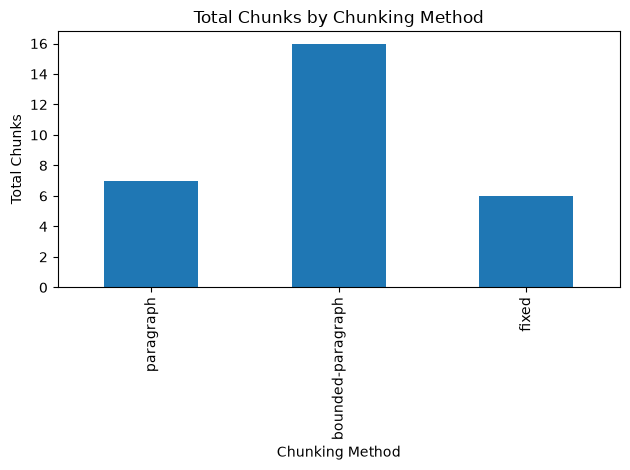

In [16]:
# Visualize the number of chunks produced by each method.

ax = comparison.plot(
    x="method",
    y="total_chunks",
    kind="bar",
    legend=False,
    title="Total Chunks by Chunking Method",
)

ax.set_xlabel("Chunking Method")
ax.set_ylabel("Total Chunks")

plt.tight_layout()
plt.show()

## Interpreting the Chunking Results

The paragraph-based method creates chunks using natural document boundaries, such as notes and short paragraphs. For Markdown files, short headings that appear by themselves are attached to the content that comes after them. This prevents headings from becoming very small separate chunks. It also makes the output easier to read and trace, although the chunk sizes may be different.

The bounded paragraph method also uses natural paragraph boundaries and follows the same rule for attaching Markdown headings. If a paragraph is too large, it is divided into smaller chunks so that each one stays within the set token limit. This makes the method useful when chunks need to fit within a model or tokenizer limit.

Bounded paragraph chunks also allow the original source text to be rebuilt exactly. Some chunks may contain blank lines or extra whitespace because these are part of the original document. Keeping this whitespace makes the chunks continuous. As a result, joining the `chunk_text` values in the correct order can recreate the full original document.

The fixed-size method creates more consistent chunk sizes because it splits the text based on word count. This can be useful for systems that work better with similar input sizes. However, this method may split text in the middle of natural sections. The overlap option helps keep some context between one chunk and the next.

Chunk IDs also depend on the chunking configuration. This means that chunks from the same source document and with the same chunk index will have different IDs if they are created using different chunking methods or settings.

## Configuration-Aware Chunk ID Check

The next cell checks that the same source document receives different chunk IDs when it is processed with different chunking configurations. This protects against ID collisions between paragraph, fixed-size, and bounded paragraph outputs.


In [17]:
# Check that chunk IDs change when the chunking configuration changes.

target_src = paragraph_df["source_path"].iloc[0]

id_rows = []

method_frames = [
    ("paragraph", paragraph_df),
    ("bounded-paragraph", bounded_df),
    ("fixed", fixed_df),
]

for method_name, frame in method_frames:
    src_rows = frame[frame["source_path"] == target_src].copy()
    src_rows = src_rows.sort_values("chunk_index")
    first_row = src_rows.iloc[0]

    id_rows.append(
        {
            "src_path": target_src,
            "method": method_name,
            "chunk_index": int(first_row["chunk_index"]),
            "chunk_size": first_row["chunk_size"],
            "overlap": first_row["overlap"],
            "max_tokens": first_row["max_tokens"],
            "tokenizer": first_row["tokenizer"],
            "chunk_id": first_row["chunk_id"],
        }
    )

id_df = pd.DataFrame(id_rows)

unique_id_cnt = len(set(id_df["chunk_id"]))
expected_id_cnt = len(id_df)
ids_are_unique = unique_id_cnt == expected_id_cnt

print("Source path checked:", target_src)
print("Configuration-aware chunk IDs are unique:", ids_are_unique)

if not ids_are_unique:
    raise AssertionError("Chunk IDs should differ across chunking configurations.")

id_df


Source path checked: campus_garden_notes.txt
Configuration-aware chunk IDs are unique: True


,src_path,method,chunk_index,chunk_size,overlap,max_tokens,tokenizer,chunk_id
0,campus_garden_notes.txt,paragraph,0,NaN,NaN,NaN,NaN,campus_garden_notes_txt_fe25b38b_paragraph_000
1,campus_garden_notes.txt,bounded-paragraph,0,NaN,NaN,20.0,cl100k_base,campus_garden_notes_txt_fe25b38b_bounded_parag...
2,campus_garden_notes.txt,fixed,0,40.0,5.0,NaN,None,campus_garden_notes_txt_fe25b38b_fixed_cs40_ov...


In [18]:
# Inspect one chunk and its traceability metadata.
# The chunk ID includes source identity, method/settings, and chunk index.

example_chunk = paragraph_df.loc[paragraph_df["word_count"].idxmax()]

print("Chunk ID:", example_chunk["chunk_id"])
print("Source file:", example_chunk["source_file"])
print("Source path:", example_chunk["source_path"])
print("Method:", example_chunk["method"])
print("Chunk index:", example_chunk["chunk_index"])
print("Character range:", f'{example_chunk["start_char"]} to {example_chunk["end_char"]}')
print("Word count:", example_chunk["word_count"])
print("Character count:", example_chunk["char_count"])
print()
print("Chunk text:")
print("-" * 80)
print(example_chunk["chunk_text"])

Chunk ID: project_meeting_notes_md_4ddcb141_paragraph_002
Source file: project_meeting_notes.md
Source path: project_meeting_notes.md
Method: paragraph
Chunk index: 2
Character range: 345 to 564
Word count: 37
Character count: 219

Chunk text:
--------------------------------------------------------------------------------
## Next Steps

- Daniel will revise the introduction.
- Maya will format the references.
- Lucas will make the first version of the slides.
- Priya will check whether the data table matches the written explanation.


## Single-Chunk Traceability Check

A key goal of this utility is that every chunk can be traced back to the original source document. The next cell verifies this for one paragraph chunk by using the stored `start_char` and `end_char` offsets to reconstruct the chunk from the original file. If the reconstructed text matches the saved chunk text, the metadata is working correctly.


In [19]:
# Verify that the stored character offsets reconstruct the original chunk text.

src_path = smpl_DOCS / example_chunk["source_path"]
src_text = read_text_file(src_path)

start_char = int(example_chunk["start_char"])
end_char = int(example_chunk["end_char"])

reconstr_text = src_text[start_char:end_char]

print("Offset reconstruction successful:", reconstr_text == example_chunk["chunk_text"])
print()
print("Reconstructed text:")
print("-" * 80)
print(reconstr_text)

Offset reconstruction successful: True

Reconstructed text:
--------------------------------------------------------------------------------
## Next Steps

- Daniel will revise the introduction.
- Maya will format the references.
- Lucas will make the first version of the slides.
- Priya will check whether the data table matches the written explanation.


## Bounded Paragraph Reconstruction Check

The next cell checks that the bounded paragraph method works correctly.

For each source document in the bounded paragraph output, it checks that:

* each exported chunk can be recreated exactly using `src_text[start_char:end_char]`,
* the chunks are continuous from the start to the end of the source file,
* joining all `chunk_text` values in order recreates the full source document exactly,
* and every chunk stays within the configured token limit.

This check is important because bounded paragraph chunks may include blank lines or extra whitespace from the original source file. Keeping this whitespace helps make sure the original document can be reconstructed exactly.

In [20]:
# Verify exact bounded paragraph reconstruction for every bounded output source file.

bounded_checks = []

for src_path_value in sorted(bounded_df["source_path"].unique()):
    src_file_path = smpl_DOCS / str(src_path_value)
    src_text = read_text_file(src_file_path)

    src_rows = bounded_df[
        bounded_df["source_path"] == src_path_value
    ].copy()
    src_rows = src_rows.sort_values("chunk_index")

    offsets_ok = True
    contiguous_ok = True
    token_limit_ok = True
    rebuilt_text = ""
    expected_start = 0

    for _, row in src_rows.iterrows():
        start_char = int(row["start_char"])
        end_char = int(row["end_char"])
        chunk_text = row["chunk_text"]

        src_slice = src_text[start_char:end_char]

        if src_slice != chunk_text:
            offsets_ok = False

        if start_char != expected_start:
            contiguous_ok = False

        expected_start = end_char
        rebuilt_text += chunk_text

        if int(row["token_count"]) > int(row["max_tokens"]):
            token_limit_ok = False

    full_reconstr_ok = rebuilt_text == src_text
    reached_src_end = expected_start == len(src_text)

    bounded_checks.append(
        {
            "src_path": src_path_value,
            "bounded_chunks": len(src_rows),
            "offsets_ok": offsets_ok,
            "contiguous_ok": contiguous_ok,
            "reached_src_end": reached_src_end,
            "full_reconstr_ok": full_reconstr_ok,
            "token_limit_ok": token_limit_ok,
        }
    )

bounded_check_df = pd.DataFrame(bounded_checks)

all_checks_passed = (
    bounded_check_df["offsets_ok"].all()
    and bounded_check_df["contiguous_ok"].all()
    and bounded_check_df["reached_src_end"].all()
    and bounded_check_df["full_reconstr_ok"].all()
    and bounded_check_df["token_limit_ok"].all()
)

print("All bounded paragraph reconstruction checks passed:", bool(all_checks_passed))

if not all_checks_passed:
    raise AssertionError("One or more bounded paragraph reconstruction checks failed.")

bounded_check_df


All bounded paragraph reconstruction checks passed: True


,src_path,bounded_chunks,offsets_ok,contiguous_ok,reached_src_end,full_reconstr_ok,token_limit_ok
0,campus_garden_notes.txt,7,True,True,True,True,True
1,project_meeting_notes.md,9,True,True,True,True,True


In [21]:
# Use the CLI inspect command to preview a bounded paragraph output file.

inspect_cmd = [
    sys.executable,
    "-m",
    "document_chunking_utility",
    "inspect",
    str(bounded_out.relative_to(PROJ_ROOT)),
    "--limit",
    "3",
]

result = subprocess.run(
    inspect_cmd,
    capture_output=True,
    text=True,
    cwd=PROJ_ROOT,
    check=False,
)

disp_cmd = inspect_cmd.copy()
disp_cmd[0] = "python"

print("Command:")
print(" ".join(disp_cmd))
print()
print("Inspect output:")
print(result.stdout)

if result.stderr:
    print("Inspect errors or warnings:")
    print(result.stderr)

if result.returncode != 0:
    raise RuntimeError("Inspect command failed.")

Command:
python -m document_chunking_utility inspect tmp/notebook_demo/demo_bounded_chunks.jsonl --limit 3

Inspect output:
Output file: tmp/notebook_demo/demo_bounded_chunks.jsonl
Format: JSONL
Total chunks: 16
Source files: 2
Methods: bounded-paragraph
Average words per chunk: 11.2
Shortest chunk: 1 word
Longest chunk: 18 words
Tokenized chunks: 16
Average tokens per chunk: 13.6
Shortest token count: 3 tokens
Longest token count: 20 tokens

Preview records: 3
[0] campus_garden_notes_txt_fe25b38b_bounded_paragraph_mt20_tk_cl100k_base_000 | campus_garden_notes.txt | 3 words | 5 tokens | Campus Garden Notes
[1] campus_garden_notes_txt_fe25b38b_bounded_paragraph_mt20_tk_cl100k_base_001 | campus_garden_notes.txt | 15 words | 17 tokens | The campus garden looks different in the morning because the east side gets s...
[2] campus_garden_notes_txt_fe25b38b_bounded_paragraph_mt20_tk_cl100k_base_002 | campus_garden_notes.txt | 18 words | 20 tokens | Most of the tomatoes are still green, but the

## Demo Summary

This demo has shown that the utility can:

* load local `.txt` and `.md` files,
* create paragraph-based chunks,
* attach short Markdown headings to the content that follows them,
* create bounded paragraph chunks with token-related metadata,
* create fixed-size word chunks with adjustable overlap,
* check that overlapping words match between nearby fixed-size chunks,
* save structured results as CSV and JSONL files,
* reload the saved files into pandas for review,
* compare chunk counts, word counts, character counts, and token statistics between different chunking methods,
* store metadata such as source file, source path, configuration-based chunk ID, chunk index, character offsets, word count, character count, token count, token limit, and tokenizer name,
* check that chunk IDs are different when the same source document is processed with different chunking methods or settings,
* check traceability by recreating a chunk from the original source document using its stored character offsets,
* verify that bounded paragraph chunks match their stored source offsets exactly,
* verify that bounded paragraph chunks can rebuild the full source document when they are joined in order,
* confirm that bounded paragraph chunks stay within the configured token limit,
* and preview generated output files using the CLI `inspect` command.